In [2]:
import random
import statistics
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 120)


## Part 1

In [3]:
class Node:
    def __init__(self, key):
        self.key = key
        self.left = None
        self.right = None


class BST:
    def __init__(self):
        self.root = None

    def insert(self, key):
        new_node = Node(key)
        if self.root is None:
            self.root = new_node
            return

        current = self.root
        while True:
            if key < current.key:
                if current.left is None:
                    current.left = new_node
                    return
                current = current.left
            else: 
                if current.right is None:
                    current.right = new_node
                    return
                current = current.right

    def search(self, key, count_comparisons=False):
        current = self.root
        comparisons = 0
        while current is not None:
            comparisons += 1 
            if key == current.key:
                if count_comparisons:
                    return True, comparisons
                return True
            elif key < current.key:
                current = current.left
            else:
                current = current.right

        if count_comparisons:
            return False, comparisons
        return False

    def inorder_traversal(self):
        result = []
        stack = []
        current = self.root
        while current is not None or stack:
            while current is not None:
                stack.append(current)
                current = current.left
            current = stack.pop()
            result.append(current.key)
            current = current.right
        return result

    def node_depths(self):
        depths = {}
        if self.root is None:
            return depths

        stack = [(self.root, 0)]
        while stack:
            node, depth = stack.pop()
            depths[node.key] = depth
            if node.right is not None:
                stack.append((node.right, depth + 1))
            if node.left is not None:
                stack.append((node.left, depth + 1))
        return depths

    def height(self):
        depths = self.node_depths()
        return max(depths.values()) if depths else -1

    def average_node_depth(self):
        depths = self.node_depths()
        return statistics.mean(depths.values()) if depths else float("nan")

    def average_successful_search_comparisons(self):
        keys = self.inorder_traversal()
        if not keys:
            return float("nan")
        counts = [self.search(key, count_comparisons=True)[1] for key in keys]
        return statistics.mean(counts)


def build_bst(insertion_order):
    tree = BST()
    for key in insertion_order:
        tree.insert(key)
    return tree


def balanced_insertion_order(sorted_keys):
    order = []

    def add_middle(first, last):
        if first >= last:
            return
        middle = (first + last) // 2
        order.append(sorted_keys[middle])
        add_middle(first, middle)
        add_middle(middle + 1, last)

    add_middle(0, len(sorted_keys))
    return order


In [4]:
verification_order = [50, 30, 70, 20, 40, 60, 80, 35, 45]
verification_tree = build_bst(verification_order)

verification_inorder = verification_tree.inorder_traversal()
verification_depths = verification_tree.node_depths()
verification_searches = {
    key: verification_tree.search(key, count_comparisons=True)[1]
    for key in [35, 60, 80]
}

print("Inorder traversal:", verification_inorder)
print("Height:", verification_tree.height())
print("Node depths (key: depth):", dict(sorted(verification_depths.items())))
print("Successful search comparisons:", verification_searches)


Inorder traversal: [20, 30, 35, 40, 45, 50, 60, 70, 80]
Height: 3
Node depths (key: depth): {20: 2, 30: 1, 35: 3, 40: 2, 45: 3, 50: 0, 60: 2, 70: 1, 80: 2}
Successful search comparisons: {35: 4, 60: 3, 80: 3}


## Part 2

In [5]:
N_VALUES = [100, 500, 1000, 2000]
RANDOM_SEEDS = list(range(100, 111))

trial_rows = []
summary_rows = []

for n in N_VALUES:
    keys = list(range(1, n + 1))

    ascending_tree = build_bst(keys)
    trial_rows.append({
        "N": n, "Strategy": "Ascending", "Trial": 1, "Seed": None,
        "Height": ascending_tree.height(),
        "Average node depth": ascending_tree.average_node_depth(),
        "Average successful search comparisons": ascending_tree.average_successful_search_comparisons()
    })

    for trial_number, seed in enumerate(RANDOM_SEEDS, start=1):
        shuffled_keys = keys.copy()
        random.Random(seed).shuffle(shuffled_keys)
        random_tree = build_bst(shuffled_keys)
        trial_rows.append({
            "N": n, "Strategy": "Random", "Trial": trial_number, "Seed": seed,
            "Height": random_tree.height(),
            "Average node depth": random_tree.average_node_depth(),
            "Average successful search comparisons": random_tree.average_successful_search_comparisons()
        })

    balanced_order = balanced_insertion_order(keys)
    balanced_tree = build_bst(balanced_order)
    trial_rows.append({
        "N": n, "Strategy": "Balanced", "Trial": 1, "Seed": None,
        "Height": balanced_tree.height(),
        "Average node depth": balanced_tree.average_node_depth(),
        "Average successful search comparisons": balanced_tree.average_successful_search_comparisons()
    })

trial_results = pd.DataFrame(trial_rows)

summary_results = (
    trial_results
    .groupby(["N", "Strategy"])
    .agg({
        "Height": "mean",
        "Average node depth": "mean",
        "Average successful search comparisons": "mean"
    })
    .reset_index()
)

summary_results


,N,Strategy,Height,Average node depth,Average successful search comparisons
0,100,Ascending,99.000000,49.500000,50.500000
1,100,Balanced,6.000000,4.800000,5.800000
2,100,Random,12.272727,6.537273,7.537273
3,500,Ascending,499.000000,249.500000,250.500000
4,500,Balanced,8.000000,6.996000,7.996000
5,500,Random,19.727273,10.075273,11.075273
6,1000,Ascending,999.000000,499.500000,500.500000
7,1000,Balanced,9.000000,7.987000,8.987000
8,1000,Random,21.909091,11.089455,12.089455
9,2000,Ascending,1999.000000,999.500000,1000.500000


## Individual random trails:

In [6]:
random_results = (
    trial_results[trial_results["Strategy"] == "Random"]
    .groupby("N")
    .agg({
        "Height": "mean",
        "Average node depth": "mean",
        "Average successful search comparisons": "mean"
    })
    .reset_index()
)

random_results

,N,Height,Average node depth,Average successful search comparisons
0,100,12.272727,6.537273,7.537273
1,500,19.727273,10.075273,11.075273
2,1000,21.909091,11.089455,12.089455
3,2000,23.363636,12.337682,13.337682


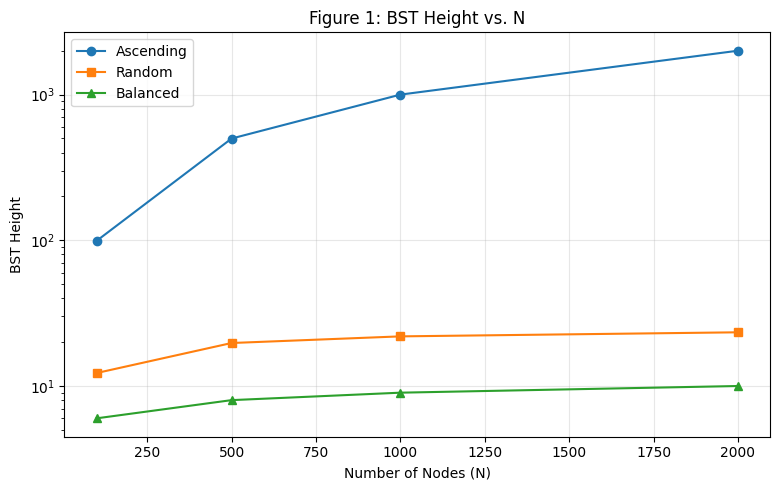

In [7]:
strategy_order = ["Ascending", "Random", "Balanced"]
markers = {"Ascending": "o", "Random": "s", "Balanced": "^"}

plt.figure(figsize=(8, 5))
for strategy in strategy_order:
    data = summary_results[summary_results["Strategy"] == strategy]
    plt.plot(data["N"], data["Height"], marker=markers[strategy], label=strategy)
plt.xlabel("Number of Nodes (N)")
plt.ylabel("BST Height")
plt.title("Figure 1: BST Height vs. N")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figure1_bst_height_vs_n.png", dpi=150)
plt.yscale('log') 
plt.show()


## Average successfuL comparisons

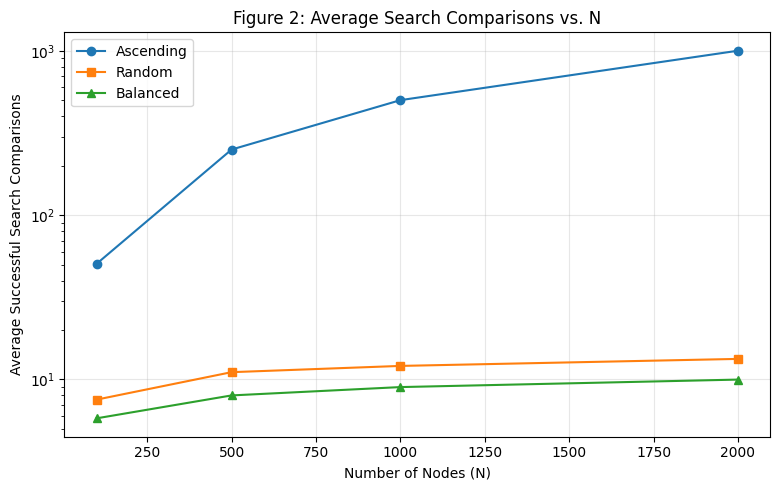

In [8]:
plt.figure(figsize=(8, 5))
for strategy in strategy_order:
    data = summary_results[summary_results["Strategy"] == strategy]
    plt.plot(data["N"], data["Average successful search comparisons"],
             marker=markers[strategy], label=strategy)
plt.xlabel("Number of Nodes (N)")
plt.ylabel("Average Successful Search Comparisons")
plt.title("Figure 2: Average Search Comparisons vs. N")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figure2_average_search_comparisons_vs_n.png", dpi=150)
plt.yscale('log') 
plt.show()


## Part 3

In [9]:
N_DEPTH = 1000
keys_depth = list(range(1, N_DEPTH + 1))

ascending_depth_tree = build_bst(keys_depth)

random_depth_seed = 100
random_depth_order = keys_depth.copy()
random.Random(random_depth_seed).shuffle(random_depth_order)
random_depth_tree = build_bst(random_depth_order)

balanced_depth_tree = build_bst(balanced_insertion_order(keys_depth))

depth_sets = {
    "Ascending": list(ascending_depth_tree.node_depths().values()),
    "Random (seed 101)": list(random_depth_tree.node_depths().values()),
    "Balanced": list(balanced_depth_tree.node_depths().values())
}

depth_summary = pd.DataFrame([
    {
        "Strategy": name,
        "Height": tree.height(),
        "Average node depth": tree.average_node_depth(),
        "Average successful search comparisons": tree.average_successful_search_comparisons()
    }
    for name, tree in [
        ("Ascending", ascending_depth_tree),
        ("Random (seed 100)", random_depth_tree),
        ("Balanced", balanced_depth_tree)
    ]
])

depth_summary


,Strategy,Height,Average node depth,Average successful search comparisons
0,Ascending,999,499.500,500.500
1,Random (seed 100),21,10.371,11.371
2,Balanced,9,7.987,8.987


## Node-depth Distirbution:

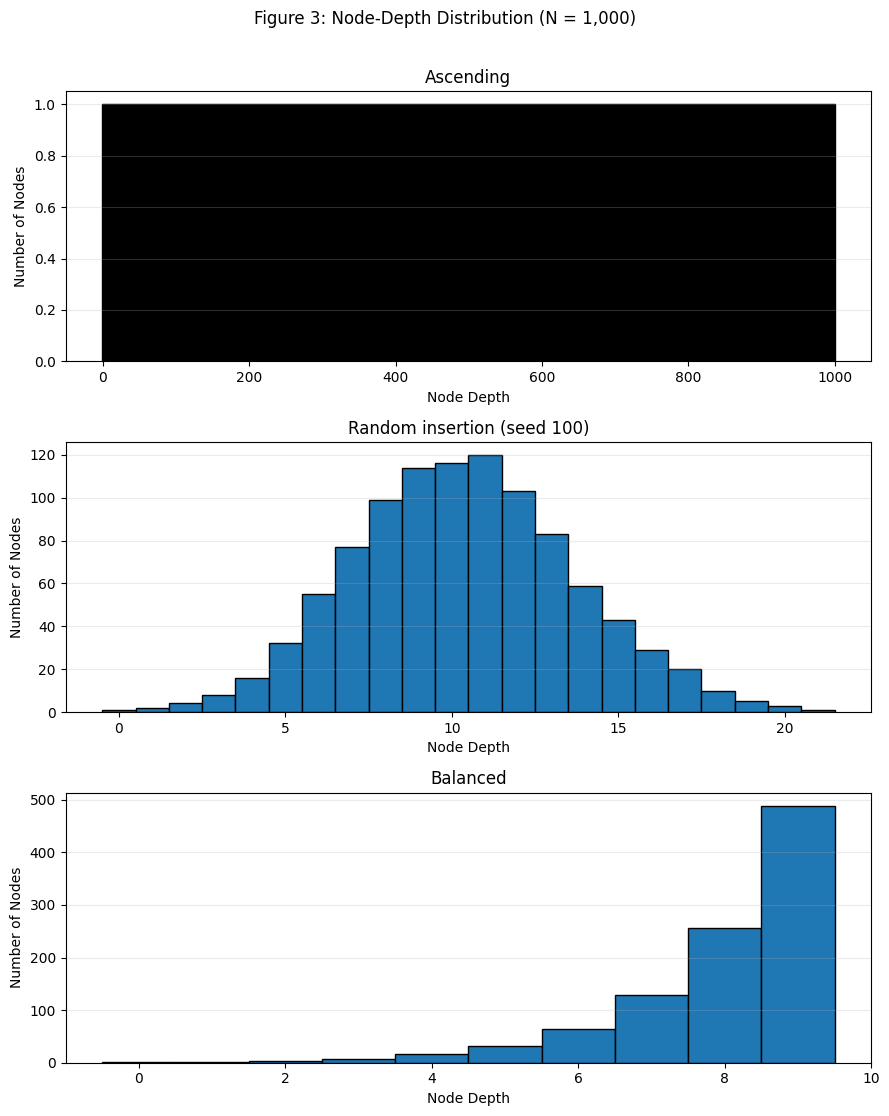

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=False, sharey=False)
histogram_specs = [
    ("Ascending", depth_sets["Ascending"]),
    ("Random insertion (seed 100)", depth_sets["Random (seed 101)"]),
    ("Balanced", depth_sets["Balanced"])
]

for ax, (title, depths) in zip(axes, histogram_specs):
    bins = np.arange(min(depths) - 0.5, max(depths) + 1.5, 1)
    ax.hist(depths, bins=bins, edgecolor="black")
    ax.set_xlabel("Node Depth")
    ax.set_ylabel("Number of Nodes")
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.25)

fig.suptitle("Figure 3: Node-Depth Distribution (N = 1,000)", y=1.01)
fig.tight_layout()
fig.savefig("figure3_node_depth_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
